# A · Oferta de cuidado y territorio (CDMX)

Fuentes territoriales y agregadas: DENUE, capacidad residencial, CSV de investigación del proyecto, CONEVAL y CONAPO.

Este notebook junta varios análisis que antes estaban separados. Cada sección conserva su **número original** y escribe los mismos archivos en `resultados/`, con el mismo prefijo. Una cifra citada como "notebook 04" se rastrea a la sección 04.

| Sección | Tema | Archivo original | Escribe |
|---|---|---|---|
| [01](#s01) | Oferta de cuidado en el DENUE | `01_denue_oferta_cuidado.ipynb` | `outputs/` |
| [02](#s02) | Capacidad residencial privada vs. población 60+ y dependiente | `02_capacidad_residencial_vs_poblacion.ipynb` | `resultados/02_*` |
| [08](#s08) | Hallazgos de los CSV de investigación | `08_hallazgos_csv_proyecto.ipynb` | `resultados/08_*` |
| [09](#s09) | CONEVAL: pobreza por grupos a escala municipal | `09_coneval_pobreza_grupos_municipal.ipynb` | `resultados/09_*` |
| [13](#s13) | Rezago social por AGEB y marginación municipal | `13_rezago_social_ageb_cdmx.ipynb` | `resultados/13_*` |

Requiere el DENUE en `Data/raw/` (no se sube a git; ver `Data/README_notebook01.md`).

Cada sección carga sus datos desde cero, así que no dependen de variables de secciones anteriores. Ejecutar con *Kernel → Restart & Run All* desde la carpeta `Analysis/`.

<a id="s01"></a>

---

*Sección 01 · antes `01_denue_oferta_cuidado.ipynb`*

# 01 · Oferta de cuidado en el DENUE — Ciudad de México

**Propósito.** Identificar qué establecimientos del DENUE corresponden a servicios de cuidado para
personas mayores y con discapacidad, contarlos por alcaldía y probar con datos propios, a escala de alcaldía,
el supuesto de "desiertos de cuidado" que hoy el informe integrador cita sin análisis que lo respalde.

**Qué NO hace este notebook.** No estima capacidad (plazas/cupos): el DENUE no la mide.
No trabaja a nivel AGEB/manzana contra demanda: eso requiere el Censo 2020 por manzana, que todavía no está en el repositorio.

**Fuentes**
| Archivo | Origen | Unidad de observación | Clave | Notas |
|---|---|---|---|---|
| `data/raw/denue_inegi_09_.csv` | INEGI, DENUE 05_2026 (modificado 2026-05-20), Términos de Libre Uso | Establecimiento | `id` / `clee` | Clasificado con **SCIAN 2018** (según su diccionario de datos) |
| `data/ref/Población de más de 60 años.csv` | Archivo del proyecto; **origen y año sin documentar** | Alcaldía × grupo de edad | `NOM_MUN` + `GRUPO_EDAD` | Valores = % de la población total de la CDMX |
| `data/ref/Capacidad disponible en residencias permanentes...csv` | Archivo del proyecto; **origen y año sin documentar** | Alcaldía | `Alcaldia` | Solo residencias privadas, 12 alcaldías |

El DENUE es un directorio: no tiene factor de expansión y cada fila es un establecimiento, no una muestra.


In [1]:
from pathlib import Path
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path('..')
RAW = RAIZ / 'data' / 'raw' / 'denue_inegi_09_.csv'
REF = RAIZ / 'data' / 'ref'
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', 80)

## 1. Carga y validación

In [2]:
denue = pd.read_csv(RAW, encoding='latin-1', dtype=str)
print('Filas:', len(denue), '| columnas:', denue.shape[1])
assert denue['id'].is_unique, 'id duplicado'
assert set(denue['cve_ent']) == {'09'}, 'hay registros fuera de la CDMX'
print('Alcaldías:', denue['cve_mun'].nunique())
print('Registros sin coordenadas:', denue[['latitud','longitud']].isna().any(axis=1).sum())

Filas: 462732 | columnas: 42
Alcaldías: 16


Registros sin coordenadas: 0


## 2. Verificación de las claves SCIAN propuestas en la delimitación

La delimitación consolidada (NotebookLM) propone `624410`, `624120` y `624310`. Esas son claves NAICS de EE. UU.;
el SCIAN México separa sector privado (terminación 1) y público (terminación 2). Se comprueba contra el propio archivo:

In [3]:
propuestas = ['624410', '624120', '624310']
print({c: int((denue['codigo_act'] == c).sum()) for c in propuestas})

(denue[denue['codigo_act'].str[:3].isin(['623', '624'])]
   .groupby(['codigo_act', 'nombre_act']).size().rename('establecimientos').to_frame())

{'624410': 0, '624120': 0, '624310': 0}


,,establecimientos
codigo_act,nombre_act,
623111,"Residencias del sector privado con cuidados de enfermeras para enfermos convalecientes, en rehabilitación, incurables y terminales",12
623112,"Residencias del sector público con cuidados de enfermeras para enfermos convalecientes, en rehabilitación, incurables y terminales",4
623211,Residencias del sector privado para el cuidado de personas con problemas de retardo mental,17
623212,Residencias del sector público para el cuidado de personas con problemas de retardo mental,1
623221,Residencias del sector privado para el cuidado de personas con problemas de trastorno mental y adicción,34
623222,Residencias del sector público para el cuidado de personas con problemas de trastorno mental y adicción,11
623311,Asilos y otras residencias del sector privado para el cuidado de ancianos,88
623312,Asilos y otras residencias del sector público para el cuidado de ancianos,21
623991,Orfanatos y otras residencias de asistencia social del sector privado,107


## 3. Catálogo de clases de cuidado (decisión del equipo, editable)

El catálogo vive en `catalogo_scian_cuidado.csv`, no en el código, para que el cambio de criterio quede versionado.
- **nucleo**: asilos y centros de día (personas mayores/discapacidad). Es lo que se usa en la comparación por alcaldía.
- **ampliado**: servicios relacionados que no son exclusivos de la población objetivo.
- **fuera_poblacion_objetivo / excluido_por_ahora**: se reportan pero no entran al análisis.

In [4]:
cat = pd.read_csv('catalogo_scian_cuidado.csv', dtype=str)
cuidado = denue.merge(cat, on='codigo_act', how='inner')
cuidado['sector'] = cuidado['codigo_act'].str[-1].map({'1': 'privado', '2': 'público'})
resumen = (cuidado.groupby(['grupo', 'codigo_act', 'nombre_act', 'sector'])
                  .size().rename('establecimientos').reset_index())
resumen

,grupo,codigo_act,nombre_act,sector,establecimientos
0,ampliado,621341,"Consultorios del sector privado de audiología y de terapia ocupacional, físi...",privado,536
1,ampliado,621342,"Consultorios del sector público de audiología y de terapia ocupacional, físi...",público,23
2,ampliado,623111,Residencias del sector privado con cuidados de enfermeras para enfermos conv...,privado,12
3,ampliado,623112,Residencias del sector público con cuidados de enfermeras para enfermos conv...,público,4
4,ampliado,623211,Residencias del sector privado para el cuidado de personas con problemas de ...,privado,17
5,ampliado,623212,Residencias del sector público para el cuidado de personas con problemas de ...,público,1
6,excluido_por_ahora,624311,Servicios de capacitación para el trabajo prestados por el sector privado pa...,privado,10
7,excluido_por_ahora,624312,Servicios de capacitación para el trabajo prestados por el sector público pa...,público,13
8,fuera_poblacion_objetivo,624411,Guarderías del sector privado,privado,340
9,fuera_poblacion_objetivo,624412,Guarderías del sector público,público,263


In [5]:
resumen.groupby('grupo')['establecimientos'].sum()

grupo
ampliado                    593
excluido_por_ahora           23
fuera_poblacion_objetivo    603
nucleo                      235
Name: establecimientos, dtype: int64

## 4. Calidad de la clasificación: revisión de nombres

La clase SCIAN la asigna el INEGI por actividad principal; no es garantía de que el lugar sea lo que dice la clase.
Se listan los nombres del núcleo que no contienen palabras típicas de cuidado, para revisión manual.

In [6]:
def norm(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode()
    return s.upper()

nucleo = cuidado[cuidado['grupo'] == 'nucleo'].copy()
patron = r'ASILO|ANCIAN|ADULTO|MAYOR|GERIATR|RESIDENCIA|ESTANCIA|CASA|HOGAR|DIA|DIF|INAPAM|ALZHEIMER|CUIDADO|ABUEL|SENIOR|VIDA|RETIRO|DISCAPACI'
nucleo['nombre_norm'] = nucleo['nom_estab'].map(norm)
dudosos = nucleo[~nucleo['nombre_norm'].str.contains(patron, regex=True)]
print(f'Núcleo: {len(nucleo)} | nombres sin palabra típica de cuidado: {len(dudosos)} ({len(dudosos)/len(nucleo):.0%})')
dudosos[['nom_estab', 'codigo_act', 'municipio', 'per_ocu']].sort_values('codigo_act')

Núcleo: 235 | nombres sin palabra típica de cuidado: 49 (21%)


,nom_estab,codigo_act,municipio,per_ocu
1283,PLENITUD EN ARMONIA,623311,Coyoacán,6 a 10 personas
1137,HERMANAS DE LA SAGRADA FAMILIA ORDEN DE SAN BENITO,623311,Gustavo A. Madero,0 a 5 personas
1147,HOSPITAL VICENTINO,623311,Álvaro Obregón,11 a 30 personas
19,ALMASANA HEALTH CLUB,623311,Miguel Hidalgo,0 a 5 personas
52,ASOCIACION DE AYUDA SOCIAL DE LA COMUNIDAD ALEMANA,623311,Xochimilco,31 a 50 personas
62,ATENCION INTEGRAL A LA SENECTUD LUZ AZTECA,623311,Iztapalapa,0 a 5 personas
80,BELMONT VILLAGE,623311,Cuajimalpa de Morelos,101 a 250 personas
1381,TECHO EDUCACION Y AYUDA,623311,La Magdalena Contreras,51 a 100 personas
1368,SMART LIFE RETIREMENT,623311,La Magdalena Contreras,0 a 5 personas
985,FUNDACION MIER Y PESADO,623311,Miguel Hidalgo,101 a 250 personas


In [7]:
dudosos[['id', 'nom_estab', 'codigo_act', 'municipio', 'per_ocu']].to_csv(OUT / 'revision_manual_nucleo.csv', index=False)

## 5. Por qué el DENUE no da capacidad

`per_ocu` es un **rango de personal ocupado**, no plazas. Un asilo con "11 a 30 personas" puede tener 10 o 80 residentes.
Convertir estratos en cupos exigiría un supuesto de razón personal/residente que hoy no tiene fuente.

In [8]:
orden = ['0 a 5 personas','6 a 10 personas','11 a 30 personas','31 a 50 personas',
         '51 a 100 personas','101 a 250 personas','251 y más personas']
pd.crosstab(nucleo['codigo_act'] + ' ' + nucleo['sector'], nucleo['per_ocu']).reindex(columns=orden, fill_value=0)

per_ocu,0 a 5 personas,6 a 10 personas,11 a 30 personas,31 a 50 personas,51 a 100 personas,101 a 250 personas,251 y más personas
row_0,,,,,,,
623311 privado,21,21,30,7,5,4,0
623312 público,8,3,8,2,0,0,0
624121 privado,12,4,6,0,0,0,0
624122 público,57,26,20,1,0,0,0


## 6. Oferta vs. población 60+ por alcaldía

Se compara la **participación** de cada alcaldía en los establecimientos del núcleo contra su **participación** en la población 60+.
El archivo de población está en % de la población total de la CDMX (las alcaldías suman el total de CDMX), así que las participaciones son comparables
aunque no tengamos conteos absolutos.

`indice = % de establecimientos / % de población 60+`. Mayor que 1: la alcaldía tiene más establecimientos de los que le tocarían por su población 60+.

**Limitaciones:** año del archivo de población desconocido; contar establecimientos no es contar plazas; que un servicio esté en una alcaldía no impide que atienda a residentes de otra.

In [9]:
def llave(s):
    s = norm(s).replace('.', '').strip()
    return {'CUAJIMALPA DE MORELOS': 'CUAJIMALPA'}.get(s, s)

p60 = pd.read_csv(REF / 'Población de más de 60 años.csv')
p60.columns = [c.strip() for c in p60.columns]
p60 = p60[p60['NOM_MUN'] != 'Ciudad de México']
pob = p60.groupby('NOM_MUN')['PORCENTAJE'].sum().reset_index()
pob['llave'] = pob['NOM_MUN'].map(llave)
pob['pct_pob60'] = pob['PORCENTAJE'] / pob['PORCENTAJE'].sum() * 100

of = nucleo.groupby('municipio').agg(establecimientos=('id', 'size'),
                                     asilos=('codigo_act', lambda s: s.isin(['623311','623312']).sum()),
                                     centros_dia=('codigo_act', lambda s: s.isin(['624121','624122']).sum()),
                                     publicos=('sector', lambda s: (s == 'público').sum())).reset_index()
of['llave'] = of['municipio'].map(llave)

comp = pob.merge(of, on='llave', how='outer', indicator=True)
assert (comp['_merge'] == 'both').all(), comp[comp['_merge'] != 'both']
comp = comp.drop(columns=['_merge', 'NOM_MUN', 'PORCENTAJE'])
comp['pct_establecimientos'] = comp['establecimientos'] / comp['establecimientos'].sum() * 100
comp['indice_oferta_vs_60'] = comp['pct_establecimientos'] / comp['pct_pob60']
comp = comp[['municipio','establecimientos','asilos','centros_dia','publicos','pct_establecimientos','pct_pob60','indice_oferta_vs_60']]
comp = comp.sort_values('indice_oferta_vs_60').reset_index(drop=True)
comp.round(2)

,municipio,establecimientos,asilos,centros_dia,publicos,pct_establecimientos,pct_pob60,indice_oferta_vs_60
0,Cuauhtémoc,7,5,2,2,2.98,6.29,0.47
1,Azcapotzalco,6,4,2,3,2.55,5.27,0.48
2,Iztacalco,6,2,4,5,2.55,4.75,0.54
3,Gustavo A. Madero,25,12,13,16,10.64,13.64,0.78
4,Venustiano Carranza,10,2,8,9,4.26,5.29,0.80
5,Iztapalapa,37,10,27,22,15.74,17.57,0.90
6,Miguel Hidalgo,11,8,3,3,4.68,4.77,0.98
7,Álvaro Obregón,22,9,13,12,9.36,8.20,1.14
8,Coyoacán,23,13,10,10,9.79,8.49,1.15
9,Tlalpan,21,15,6,3,8.94,7.30,1.22


### 6b. El resultado cambia según el tipo de servicio

La clase `624121/624122` mezcla centros de día de cuidado con clubes, grupos y "casas del adulto mayor" de carácter recreativo:
el SCIAN no distingue la intensidad del cuidado. Por eso se calcula el índice por separado para asilos (residencial) y para centros de día.

In [10]:
tipo = comp[['municipio', 'asilos', 'centros_dia', 'pct_pob60']].copy()
for c in ['asilos', 'centros_dia']:
    tipo[f'indice_{c}'] = (tipo[c] / tipo[c].sum() * 100) / tipo['pct_pob60']
etiqueta = nucleo['nom_estab'].map(norm).str.contains(r'CLUB|GRUPO|REUNION|CASA DEL ADULTO', regex=True)
print('Centros de día cuyo nombre indica club/grupo/casa del adulto mayor:',
      int((etiqueta & nucleo['codigo_act'].isin(['624121','624122'])).sum()),
      'de', int(nucleo['codigo_act'].isin(['624121','624122']).sum()))
tipo.sort_values('indice_asilos').round(2)

Centros de día cuyo nombre indica club/grupo/casa del adulto mayor: 59 de 126


,municipio,asilos,centros_dia,pct_pob60,indice_asilos,indice_centros_dia
15,Milpa Alta,0,6,1.10,0.00,4.32
4,Venustiano Carranza,2,8,5.29,0.35,1.20
2,Iztacalco,2,4,4.75,0.39,0.67
5,Iztapalapa,10,27,17.57,0.52,1.22
12,Tláhuac,2,8,3.10,0.59,2.05
1,Azcapotzalco,4,2,5.27,0.70,0.30
0,Cuauhtémoc,5,2,6.29,0.73,0.25
3,Gustavo A. Madero,12,13,13.64,0.81,0.76
7,Álvaro Obregón,9,13,8.20,1.01,1.26
8,Coyoacán,13,10,8.49,1.41,0.94


In [11]:
tipo.round(3).to_csv(OUT / 'indice_por_tipo_servicio.csv', index=False)

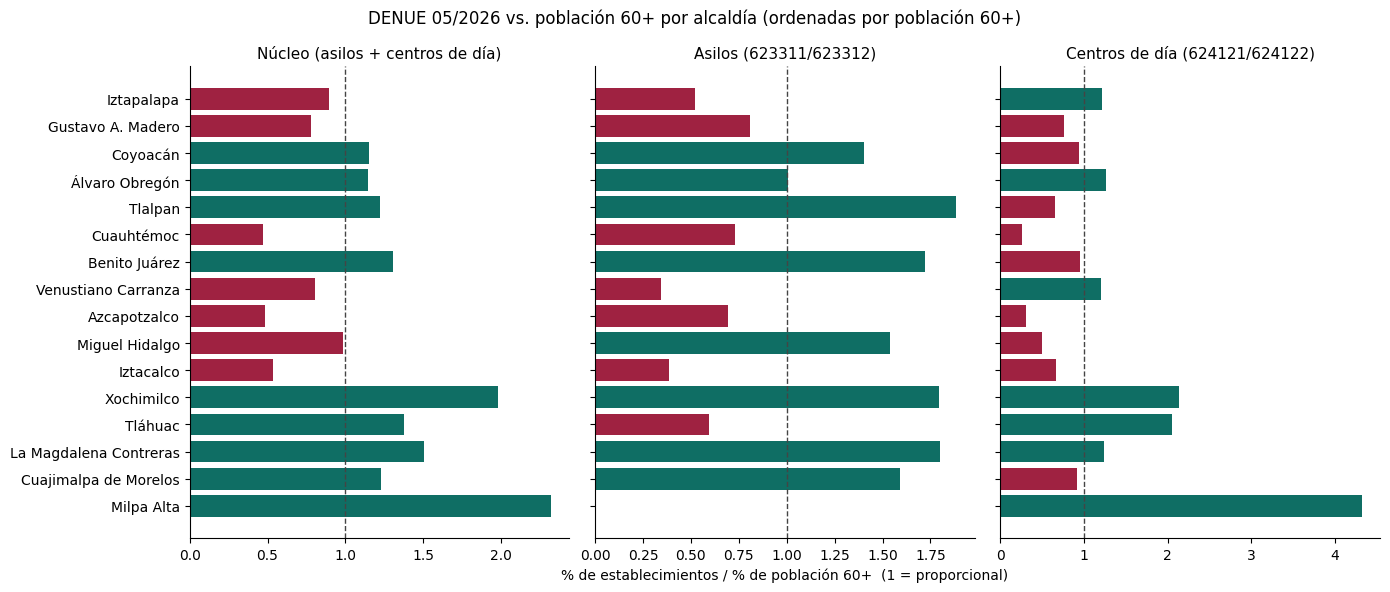

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 6), sharey=True)
orden_m = comp.sort_values('pct_pob60')['municipio']
t = tipo.set_index('municipio').loc[orden_m]
c = comp.set_index('municipio').loc[orden_m]
paneles = [(c['indice_oferta_vs_60'], 'Núcleo (asilos + centros de día)'),
           (t['indice_asilos'], 'Asilos (623311/623312)'),
           (t['indice_centros_dia'], 'Centros de día (624121/624122)')]
for ax, (serie, titulo) in zip(axes, paneles):
    ax.barh(serie.index, serie.values, color=['#9F2241' if v < 1 else '#0F6E64' for v in serie.values])
    ax.axvline(1, color='#444', lw=1, ls='--')
    ax.set_title(titulo, fontsize=11)
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
axes[1].set_xlabel('% de establecimientos / % de población 60+  (1 = proporcional)')
fig.suptitle('DENUE 05/2026 vs. población 60+ por alcaldía (ordenadas por población 60+)', fontsize=12)
plt.tight_layout(); plt.savefig(OUT / 'indice_oferta_vs_60_por_alcaldia.png', dpi=150); plt.show()

## 7. Contraste con el archivo de capacidad de residencias privadas

Si el DENUE fuera buen indicador de oferta, las alcaldías con más asilos privados (`623311`) deberían tener más capacidad.

In [13]:
cap = pd.read_csv(REF / 'Capacidad disponible en residencias permanentes de sector privado para adultos y adultas mayores.csv')
cap.columns = [c.strip() for c in cap.columns]
cap['llave'] = cap['Alcaldia'].map(llave)
asil_priv = (nucleo[nucleo['codigo_act'] == '623311'].groupby('municipio').size()
             .rename('asilos_privados_denue').reset_index())
asil_priv['llave'] = asil_priv['municipio'].map(llave)
cc = asil_priv.merge(cap[['llave', 'Capacidad_total']], on='llave', how='outer')
cc['municipio'] = cc['municipio'].fillna(cc['llave'].str.title())
cc = cc[['municipio', 'asilos_privados_denue', 'Capacidad_total']].sort_values('Capacidad_total', ascending=False)
print('Correlación de Spearman (alcaldías con ambos datos):',
      round(cc.dropna()[['asilos_privados_denue', 'Capacidad_total']].corr(method='spearman').iloc[0, 1], 2),
      '| n =', len(cc.dropna()))
cc

Correlación de Spearman (alcaldías con ambos datos): 0.27 | n = 12


,municipio,asilos_privados_denue,Capacidad_total
10,Miguel Hidalgo,7,439.0
11,Tlalpan,15,403.0
3,Coyoacán,11,361.0
5,Cuauhtémoc,5,197.0
1,Azcapotzalco,3,186.0
13,Xochimilco,7,158.0
0,Álvaro Obregón,7,140.0
2,Benito Juárez,8,102.0
9,La Magdalena Contreras,4,91.0
6,Gustavo A. Madero,8,76.0


## 8. Exportar resultados

In [14]:
comp.to_csv(OUT / 'oferta_nucleo_vs_pob60_por_alcaldia.csv', index=False)
resumen.to_csv(OUT / 'resumen_clases_cuidado.csv', index=False)
cc.to_csv(OUT / 'asilos_denue_vs_capacidad.csv', index=False)
sorted(p.name for p in OUT.iterdir())

['asilos_denue_vs_capacidad.csv',
 'indice_oferta_vs_60_por_alcaldia.png',
 'indice_por_tipo_servicio.csv',
 'oferta_nucleo_vs_pob60_por_alcaldia.csv',
 'resumen_clases_cuidado.csv',
 'revision_manual_nucleo.csv']

## 9. Qué permite afirmar este análisis y qué no

**Permite afirmar** (con las cifras de las tablas anteriores):
- Qué claves SCIAN existen en el DENUE para cuidado y cuántos establecimientos hay en cada una.
- La distribución por alcaldía de asilos y centros de día registrados, y su relación con la participación de cada alcaldía en la población 60+.

**No permite afirmar:**
- Capacidad, cupos o cobertura (el DENUE no los mide).
- "Desiertos de cuidado" a nivel AGEB o manzana (este análisis es por alcaldía y no incluye demanda por manzana).
- Que la oferta formal sea insuficiente en términos absolutos: el índice es relativo entre alcaldías.
- Nada sobre cuidado no remunerado ni sobre personas cuidadoras.
- Conclusiones finas por alcaldía: hay entre 0 y 15 asilos por alcaldía, así que un solo establecimiento mueve mucho el índice (Milpa Alta pasa de 0 a otro valor con un registro).
- Que una "casa del adulto mayor" o un club registrado en `624122` preste cuidado: la clase no distingue cuidado de recreación.

**Pendiente para subir la resolución:** Censo 2020 por manzana (población 60+ y con discapacidad), revisión manual de `outputs/revision_manual_nucleo.csv`
y documentar origen y año de los dos archivos de referencia.

<a id="s02"></a>

---

*Sección 02 · antes `02_capacidad_residencial_vs_poblacion.ipynb`*

# 02 — Capacidad residencial privada frente a población 60+ y dependiente, por alcaldía

**Para qué decisión existe este notebook.** Saber si el faltante de oferta residencial en el oriente, que salió en `01_denue_oferta_cuidado.ipynb` (conteo de establecimientos), se sostiene al medir **capacidad (plazas)** contra **población 60+**, y no contra conteos.
Esto importa para el programa. Si el problema es escasez, un matching no lo resuelve.

**Estado:** exploratorio. Resultado en nivel **probable**, no confirmado (ver sección 5).

**Métrica principal.** Cociente de localización (QL):

$$QL_i = \frac{\text{plazas}_i / \sum \text{plazas}}{\text{población}_i / \sum \text{población}}$$

QL = 1 significa que la alcaldía tiene la parte de la capacidad que le corresponde por su población. QL < 1 significa que está subrepresentada.
Se usa QL porque el archivo de población 60+ viene **en porcentaje del total de la CDMX**, no en personas. Con esta métrica no hace falta inventar un total de población.

In [15]:
from pathlib import Path
import unicodedata
import pandas as pd
from scipy.stats import spearmanr

DATA_DIR = Path('datos')        # carpeta con los CSV tal como están en el Project
OUT_DIR = Path('resultados'); OUT_DIR.mkdir(exist_ok=True)
pd.set_option('display.width', 160)

F_CAP  = 'Capacidad disponible en residencias permanentes de sector privado para adultos y adultas mayores.csv'
F_DISC = 'Población con discapacidad que necesita ayuda para las actividades de la vida diaria.csv'
F_P60  = 'Población de más de 60 años.csv'
F_PROY = 'Proyección de la población por grupos de edad y alcaldía en porcentaje.csv'
F_PUB  = 'Centros de día para adultos y adultas mayores del sector público.csv'

def leer(f):
    df = pd.read_csv(DATA_DIR / f)
    df.columns = [c.strip() for c in df.columns]   # los CSV traen espacios al inicio del encabezado
    return df

cap, disc, p60, proy, pub = (leer(f) for f in [F_CAP, F_DISC, F_P60, F_PROY, F_PUB])
for n, d in zip(['cap','disc','p60','proy','pub'], [cap, disc, p60, proy, pub]):
    print(f'{n:5s}', d.shape, list(d.columns))

cap   (12, 3) ['Alcaldia', 'Capacidad_total', 'Nomenclartura alcaldia']
disc  (204, 4) ['tipo', 'total', 'alcaldia', 'poblacion']
p60   (102, 3) ['NOM_MUN', 'GRUPO_EDAD', 'PORCENTAJE']
proy  (7616, 6) ['MUN', 'AÑO', 'SEXO', 'NOM_ENT', 'EDAD_QUIN', 'PORCENTAJE']
pub   (33, 3) ['Tipo', 'Municipio', 'Numero_instituciones']


## 1. Llave común de alcaldía

Cada archivo nombra las alcaldías distinto: con o sin acento, en mayúsculas, "Cuajimalpa de Morelos" o "CUAJIMALPA", o claves como `IZTAP`. Todo se normaliza a la clave corta que usan los archivos de discapacidad y capacidad.

In [16]:
def norm(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower().strip()
    return s.replace(' de morelos', '').replace('.', '')

CLAVE = {'alvaro obregon':'AO','azcapotzalco':'AZC','benito juarez':'BJ','coyoacan':'COY','cuajimalpa':'CUAJ',
         'cuauhtemoc':'CUAU','gustavo a madero':'GAM','iztacalco':'IZTAC','iztapalapa':'IZTAP',
         'la magdalena contreras':'MC','miguel hidalgo':'MH','milpa alta':'MA','tlahuac':'TLAH',
         'tlalpan':'TLAL','venustiano carranza':'VC','xochimilco':'XOCH'}
ALCALDIAS = sorted(CLAVE.values())

p60['clave']  = p60['NOM_MUN'].map(norm).map(CLAVE)
proy['clave'] = proy['MUN'].map(norm).map(CLAVE)
pub['clave']  = pub['Municipio'].map(norm).map(CLAVE)
cap['clave']  = cap['Nomenclartura alcaldia']
# Filas que no son alcaldía: deben ser solo los totales CDMX
print('p60 sin clave:', p60.loc[p60.clave.isna(), 'NOM_MUN'].unique())
print('proy sin clave:', proy.loc[proy.clave.isna(), 'MUN'].unique())
print('pub sin clave:', pub.loc[pub.clave.isna(), 'Municipio'].unique())
print('cap: alcaldías presentes =', cap.clave.nunique(), '| faltan:', sorted(set(ALCALDIAS) - set(cap.clave)))

p60 sin clave: ['Ciudad de México']
proy sin clave: ['CDMX']
pub sin clave: []
cap: alcaldías presentes = 12 | faltan: ['CUAJ', 'MA', 'TLAH', 'VC']


## 2. Qué representa cada archivo (fichas)

Lo que se puede verificar **dentro del archivo** se comprueba en código. Lo que no se puede verificar (institución productora, año, licencia) queda como **desconocido**. No se rellena con suposiciones.

In [17]:
# Chequeo: en el archivo 60+, ¿las alcaldías suman exactamente la fila CDMX? Si sí, el porcentaje es del total de población de la CDMX.
suma = p60[p60.clave.notna()].groupby('GRUPO_EDAD').PORCENTAJE.sum()
cdmx = p60[p60.clave.isna()].set_index('GRUPO_EDAD').PORCENTAJE
chk = pd.DataFrame({'suma_alcaldias': suma, 'fila_CDMX': cdmx}); chk['dif'] = chk.suma_alcaldias - chk.fila_CDMX
print(chk.round(6)); print('60+ como % de la población total CDMX:', round(cdmx.sum(), 2))

              suma_alcaldias  fila_CDMX  dif
GRUPO_EDAD                                  
60 a 64 años        5.097555   5.097555 -0.0
65 a 69 años        3.867353   3.867353 -0.0
70 a 74 años        2.907010   2.907010  0.0
75 a 79 años        1.902281   1.902281  0.0
80 a 84 años        1.275523   1.275523  0.0
85 y más            1.145099   1.145099  0.0
60+ como % de la población total CDMX: 16.19


**Año del archivo 60+.** El archivo no tiene año. Para acotarlo se compara con la proyección, que sí tiene años (2015–2030). En el grupo de 60 a 64 años, se busca el año de la proyección cuya distribución por alcaldía más se parece a la del archivo.

In [18]:
a = (proy[(proy.EDAD_QUIN == '60 a 64 años') & proy.clave.notna()]
       .groupby(['AÑO', 'clave']).PORCENTAJE.sum().rename('proy').reset_index())
b = p60[(p60.GRUPO_EDAD == '60 a 64 años') & p60.clave.notna()][['clave', 'PORCENTAJE']].rename(columns={'PORCENTAJE': 'p60'})
m = a.merge(b, on='clave')
difs = m.assign(d=(m.proy - m.p60).abs()).groupby('AÑO').d.agg(['max', 'mean']).round(4)
print(difs)
print('Año más cercano:', difs['max'].idxmin(), '— ¿coincidencia exacta?', bool(difs['max'].min() < 1e-6))

         max    mean
AÑO                 
2015  0.1823  0.0526
2016  0.1494  0.0424
2017  0.1203  0.0335
2018  0.0920  0.0258
2019  0.0648  0.0198
2020  0.0389  0.0150
2021  0.0399  0.0124
2022  0.0488  0.0139
2023  0.0569  0.0185
2024  0.0642  0.0230
2025  0.0708  0.0280
2026  0.0771  0.0329
2027  0.0913  0.0378
2028  0.1056  0.0431
2029  0.1199  0.0487
2030  0.1343  0.0547
Año más cercano: 2020 — ¿coincidencia exacta? False


**Lectura:** el archivo 60+ se parece más a **2020**, pero **no coincide exactamente** con ningún año de la proyección (diferencia máxima ≈ 0.04 puntos). Es otra fuente.
Que sea el Censo 2020 es **probable, no confirmado**: la cercanía a 2020 lo sugiere, pero hay que verificarlo con quien descargó el archivo.

In [19]:
fichas = pd.DataFrame([
  dict(archivo=F_P60, unidad_observacion='alcaldía × grupo quinquenal 60+', grano='16 alcaldías + total CDMX × 6 grupos',
       clave='NOM_MUN + GRUPO_EDAD', medida='% de la población TOTAL de la CDMX (verificado: alcaldías suman fila CDMX)',
       anio='desconocido; más cercano a 2020 contra la proyección, sin coincidencia exacta', productor='desconocido',
       factor_expansion='no aplica / desconocido', observaciones_independientes='no (composicional)'),
  dict(archivo=F_CAP, unidad_observacion='alcaldía', grano='12 alcaldías (faltan VC, TLAH, CUAJ, MA)',
       clave='Nomenclartura alcaldia', medida='plazas en residencias permanentes privadas',
       anio='desconocido', productor='desconocido',
       factor_expansion='no aplica', observaciones_independientes='sí'),
  dict(archivo=F_DISC, unidad_observacion='alcaldía × tipo (Limitación/Discapacidad) × actividad', grano='16 alcaldías + CDMX',
       clave='alcaldia + tipo + poblacion', medida='personas (conteo), TODAS las edades',
       anio='desconocido; la tipología limitación/discapacidad es la del Censo 2020 (probable)', productor='desconocido',
       factor_expansion='desconocido (si es cuestionario ampliado, ya viene expandido)', observaciones_independientes='no: una persona puede estar en varias actividades'),
  dict(archivo=F_PROY, unidad_observacion='alcaldía × año × sexo × grupo quinquenal', grano='2015–2030',
       clave='MUN + AÑO + SEXO + EDAD_QUIN', medida='% de la población total CDMX (suma 200 por año: 100 alcaldías + 100 fila CDMX)',
       anio='2015–2030 (proyección)', productor='desconocido',
       factor_expansion='no aplica', observaciones_independientes='no (composicional)'),
  dict(archivo=F_PUB, unidad_observacion='alcaldía × tipo de institución', grano='33 filas',
       clave='Tipo + Municipio', medida='número de instituciones (NO capacidad)',
       anio='desconocido', productor='desconocido',
       factor_expansion='no aplica', observaciones_independientes='sí'),
])
fichas.to_csv(OUT_DIR / '02_fichas_fuentes.csv', index=False, encoding='utf-8-sig')
fichas[['archivo', 'medida', 'anio']]

,archivo,medida,anio
0,Población de más de 60 años.csv,% de la población TOTAL de la CDMX (verificado: alcaldías suman fila CDMX),"desconocido; más cercano a 2020 contra la proyección, sin coincidencia exacta"
1,Capacidad disponible en residencias permanentes de sector privado para adult...,plazas en residencias permanentes privadas,desconocido
2,Población con discapacidad que necesita ayuda para las actividades de la vid...,"personas (conteo), TODAS las edades",desconocido; la tipología limitación/discapacidad es la del Censo 2020 (prob...
3,Proyección de la población por grupos de edad y alcaldía en porcentaje.csv,% de la población total CDMX (suma 200 por año: 100 alcaldías + 100 fila CDMX),2015–2030 (proyección)
4,Centros de día para adultos y adultas mayores del sector público.csv,número de instituciones (NO capacidad),desconocido


## 3. Denominadores

Se usan tres denominadores para ver si el resultado depende de cuál se elige:
- **60+**: toda la población de 60 años y más.
- **80+**: grupos 80–84 y 85+. Es la población que más probablemente necesita una residencia.
- **ADL**: personas con *discapacidad* para bañarse, vestirse o comer. Es de **todas las edades**, porque el archivo no separa por edad.

In [20]:
pob = pd.DataFrame(index=ALCALDIAS)
x = p60[p60.clave.notna()]
pob['p60'] = x.groupby('clave').PORCENTAJE.sum()
pob['p80'] = x[x.GRUPO_EDAD.isin(['80 a 84 años', '85 y más'])].groupby('clave').PORCENTAJE.sum()
pob['adl'] = (disc[(disc.tipo == 'Discapacidad') & (disc.poblacion == 'para bañarse, vestirse o comer') & (disc.alcaldia != 'CDMX')]
              .set_index('alcaldia').total)
pob['plazas'] = cap.set_index('clave').Capacidad_total
pob

,p60,p80,adl,plazas
AO,1.328108,0.199024,6653,140.0
AZC,0.853968,0.140511,4220,186.0
BJ,0.948366,0.159013,3786,102.0
COY,1.374514,0.216494,6310,361.0
CUAJ,0.280154,0.035950,1448,NaN
CUAU,1.018562,0.154344,4680,197.0
GAM,2.209232,0.363042,11935,76.0
IZTAC,0.769896,0.130153,4088,14.0
IZTAP,2.845446,0.358830,16076,20.0
MA,0.178318,0.023181,1252,NaN


## 4. Cociente de localización (QL)

Hay 4 alcaldías sin dato de capacidad y no sabemos si eso significa **0 plazas** o **dato faltante**. Por eso se calculan dos escenarios:
- **A — excluidas:** las 4 alcaldías salen del cálculo y las participaciones se calculan solo sobre las 12 que tienen dato.
- **B — cero:** las 4 alcaldías cuentan con 0 plazas y entran en las participaciones.

In [21]:
def ql(df, den):
    return (df.plazas / df.plazas.sum()) / (df[den] / df[den].sum())

A = pob.dropna(subset=['plazas']).copy()
B = pob.assign(plazas=pob.plazas.fillna(0))
res = pd.DataFrame(index=ALCALDIAS)
for den in ['p60', 'p80', 'adl']:
    res[f'QL_{den}_A'] = ql(A, den)
    res[f'QL_{den}_B'] = ql(B, den)
res['plazas'] = pob.plazas
res['plazas_por_1000_adl'] = pob.plazas / pob.adl * 1000
res = res.sort_values('QL_p60_B').round(2)
res.to_csv(OUT_DIR / '02_indice_capacidad_residencial.csv', encoding='utf-8-sig')
res

,QL_p60_A,QL_p60_B,QL_p80_A,QL_p80_B,QL_adl_A,QL_adl_B,plazas,plazas_por_1000_adl
CUAJ,NaN,0.00,NaN,0.00,NaN,0.00,NaN,NaN
VC,NaN,0.00,NaN,0.00,NaN,0.00,NaN,NaN
TLAH,NaN,0.00,NaN,0.00,NaN,0.00,NaN,NaN
MA,NaN,0.00,NaN,0.00,NaN,0.00,NaN,NaN
IZTAP,0.05,0.05,0.06,0.06,0.04,0.05,20.0,1.24
IZTAC,0.12,0.13,0.11,0.12,0.11,0.13,14.0,3.42
GAM,0.23,0.25,0.21,0.23,0.21,0.24,76.0,6.37
AO,0.69,0.78,0.70,0.78,0.70,0.80,140.0,21.04
BJ,0.71,0.80,0.63,0.71,0.90,1.03,102.0,26.94
CUAU,1.27,1.43,1.26,1.41,1.41,1.60,197.0,42.09


In [22]:
# ¿El orden de las alcaldías cambia según el denominador? (Escenario A: solo las 12 con dato)
r = res.dropna(subset=['QL_p60_A'])
for a_, b_ in [('QL_p60_A', 'QL_p80_A'), ('QL_p60_A', 'QL_adl_A'), ('QL_p80_A', 'QL_adl_A')]:
    rho, p = spearmanr(r[a_], r[b_]); print(f'{a_} vs {b_}: rho={rho:.2f}  p={p:.3f}  n={len(r)}')

bajo = {c: set(res.index[res[c] < 0.5]) for c in ['QL_p60_A', 'QL_p80_A', 'QL_adl_A']}
print('\nQL < 0.5 en los tres denominadores (A):', sorted(set.intersection(*bajo.values())))
print('Participación de Iztapalapa: 60+ =', round(pob.p60['IZTAP'] / pob.p60.sum() * 100, 1), '%  | plazas (A) =',
      round(pob.plazas['IZTAP'] / pob.plazas.sum() * 100, 1), '%')

QL_p60_A vs QL_p80_A: rho=0.99  p=0.000  n=12
QL_p60_A vs QL_adl_A: rho=0.97  p=0.000  n=12
QL_p80_A vs QL_adl_A: rho=0.94  p=0.000  n=12

QL < 0.5 en los tres denominadores (A): ['GAM', 'IZTAC', 'IZTAP']
Participación de Iztapalapa: 60+ = 17.6 %  | plazas (A) = 0.9 %


### ¿La oferta pública compensa?

El archivo público trae **número de instituciones, no plazas**. Además, la mayoría son *clubes*, que no son cuidado residencial.
Aquí solo se cuentan albergues, residencias de día y residencias permanentes, para ver si el sector público cubre donde falta oferta privada. Es indicativo, no es una medida de capacidad.

In [23]:
pub_res = (pub[pub.Tipo.isin(['ALBERGUE', 'RESIDENCIA DE DIA', 'RESIDENCIAS PERMANENTES'])]
           .groupby(['clave', 'Tipo']).Numero_instituciones.sum().unstack(fill_value=0))
comp = res[['QL_p60_B', 'plazas']].join(pub_res).fillna(0)
comp['pub_no_club_total'] = comp[[c for c in pub_res.columns]].sum(axis=1)
comp.sort_values('QL_p60_B')

,QL_p60_B,plazas,ALBERGUE,RESIDENCIA DE DIA,RESIDENCIAS PERMANENTES,pub_no_club_total
CUAJ,0.00,0.0,0.0,0.0,0.0,0.0
VC,0.00,0.0,0.0,1.0,0.0,1.0
TLAH,0.00,0.0,0.0,0.0,0.0,0.0
MA,0.00,0.0,0.0,0.0,0.0,0.0
IZTAP,0.05,20.0,1.0,0.0,0.0,1.0
IZTAC,0.13,14.0,0.0,0.0,0.0,0.0
GAM,0.25,76.0,1.0,2.0,2.0,5.0
AO,0.78,140.0,3.0,2.0,0.0,5.0
BJ,0.80,102.0,7.0,2.0,0.0,9.0
CUAU,1.43,197.0,0.0,0.0,0.0,0.0


## 5. Qué permite afirmar este resultado y qué no

Ver las tablas de arriba. Los números se leen de `resultados/02_indice_capacidad_residencial.csv`, no se copian a mano al documento.

**Permite afirmar (probable):**
- La capacidad residencial *privada* está muy por debajo de lo proporcional en Iztapalapa (QL ≈ 0.05: tiene cerca del 18% de la población 60+ y menos del 1% de las plazas), Iztacalco y Gustavo A. Madero. Esto se cumple con los tres denominadores y en los dos escenarios.
- El resultado no depende de usar 60+ o 80+. Cambia poco con el denominador ADL.
- En Iztapalapa e Iztacalco el sector público tampoco compensa: tienen 1 y 0 instituciones públicas que no son clubes. Gustavo A. Madero sí tiene 5, incluidas las únicas 2 residencias permanentes públicas del archivo. Pero son conteos de instituciones, no plazas, así que su faltante residencial es menos claro.

**No permite afirmar:**
- Que exista **demanda no atendida** de residencias. Puede haber pocas plazas privadas porque la gente no las puede pagar o porque no las quiere. La ENASIC 2022 (nacional) muestra rechazo cultural a las residencias (ver `enasic_2022_cifras_presentacion.csv`).
- Que la gente de esas alcaldías no tenga acceso a plazas. Las plazas de Miguel Hidalgo o Tlalpan no son exclusivas de sus residentes.
- Nada sobre capacidad **pública** ni sobre VC, TLAH, CUAJ y MA en el escenario A.
- Tendencias en el tiempo: hay un solo corte y su año es desconocido.

**Pendiente para pasar a confirmado:** productor, año y método de captura del CSV de capacidad; saber si las 4 alcaldías ausentes valen 0 o son dato faltante; verificar que el archivo 60+ sea del Censo 2020.

<a id="s08"></a>

---

*Sección 08 · antes `08_hallazgos_csv_proyecto.ipynb`*

# 08 - Hallazgos de los CSV de investigacion del proyecto.

```text
Proyecto integrador 7.o semestre LCDN - Observatorio de Datos para la Economia del Cuidado.
Creado: 2026-09-23. Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/

Exploratorio. Los CSV de Data/investigacion no documentan productor, anio ni cobertura
(ver seccion 7.2 del Documento Integrado): todo resultado de este script es PROBABLE y
no debe citarse hasta que se documente la fuente.
```

*Convertido de `08_hallazgos_csv_proyecto.py` el 2026-10-07 sin cambiar el cálculo; se agregaron las gráficas al final.*

In [24]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from estilo_graficas import *
estilo()
%matplotlib inline

In [25]:
from pathlib import Path
import pandas as pd

RAIZ = Path('..') if not Path('Data').exists() else Path('.')
D = RAIZ / 'Data/investigacion'
OUT = RAIZ / 'Analysis/resultados'
OUT.mkdir(parents=True, exist_ok=True)


def leer(nombre):
    df = pd.read_csv(D / nombre, encoding='utf-8-sig')
    df.columns = [c.strip() for c in df.columns]
    return df

In [26]:
# H-T1: dependencia severa (discapacidad para banarse, vestirse o comer) por alcaldia
avd = leer('Población con discapacidad que necesita ayuda para las actividades de la vida diaria.csv')
sev = avd[(avd.tipo == 'Discapacidad') & avd.poblacion.str.contains('bañarse')]
tot_cdmx = int(sev.loc[sev.alcaldia == 'CDMX', 'total'].iloc[0])
alc = sev[sev.alcaldia != 'CDMX'][['alcaldia', 'total']].copy()
assert alc.total.sum() == tot_cdmx, 'las alcaldias no suman el total CDMX'
alc['pct_cdmx'] = (100 * alc.total / tot_cdmx).round(1)
alc = alc.sort_values('total', ascending=False)
alc.to_csv(OUT / '08_dependencia_severa_alcaldia.csv', index=False)

In [27]:
# H-T2: horas de cuidado y laborales por sexo y edad
h = leer('Horas laborales y de cuidado..csv')
w = h.pivot_table(index=['Edad', 'Sexo'], columns='Tipo de trabajo', values='Horas').reset_index()
w['total'] = w['Cuidado'] + w['Laboral']
w.to_csv(OUT / '08_horas_cuidado_laboral.csv', index=False)
c = h[h['Tipo de trabajo'] == 'Cuidado'].pivot(index='Edad', columns='Sexo', values='Horas')
c['razon_M_H'] = (c['Mujeres'] / c['Hombres']).round(2)
c.reset_index().to_csv(OUT / '08_brecha_cuidado_sexo.csv', index=False)

In [28]:
# Calidad de datos
a = leer('Tiempo promedio en ayudas no pagadas a otros hogares.csv')
g = leer('Promedio del gasto en cuidados privados.csv')
pd.DataFrame([
    {'archivo': 'Tiempo promedio en ayudas no pagadas a otros hogares', 'chequeo': 'max total_horas',
     'valor': int(a.total_horas.max()), 'nota': 'incompatible con un promedio semanal (maximo posible 168 h)'},
    {'archivo': 'Promedio del gasto en cuidados privados', 'chequeo': 'categorias distintas',
     'valor': g.tipo_gasto.nunique(), 'nota': '; '.join(sorted(g.tipo_gasto.unique()))},
]).to_csv(OUT / '08_calidad_datos.csv', index=False)

print(alc.head(4).to_string(index=False))
print(c.to_string())

alcaldia  total  pct_cdmx
   IZTAP  16076      19.3
     GAM  11935      14.3
      AO   6653       8.0
     COY   6310       7.6
Sexo   Hombres  Mujeres  razon_M_H
Edad                              
11-17      9.7     15.4       1.59
18-29     15.2     31.6       2.08
30-39     14.8     28.6       1.93
40-49     16.6     26.2       1.58
50-59     16.4     24.4       1.49
60-69     19.1     23.8       1.25
70-79     25.4     28.2       1.11
80-89     45.0     27.1       0.60
90-99      NaN     18.5        NaN


## Gráficas
Archivos sin productor ni año documentados: sirven para ver la forma, no para citar niveles (evidencia: probable).

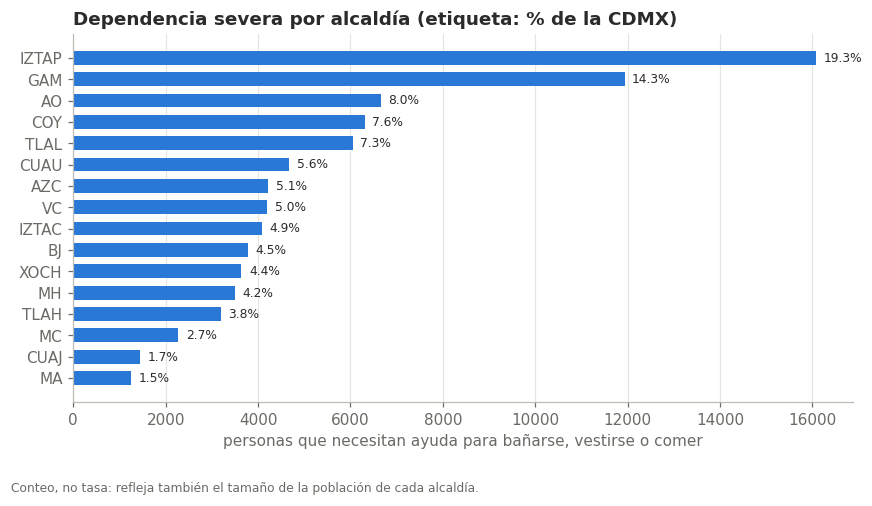

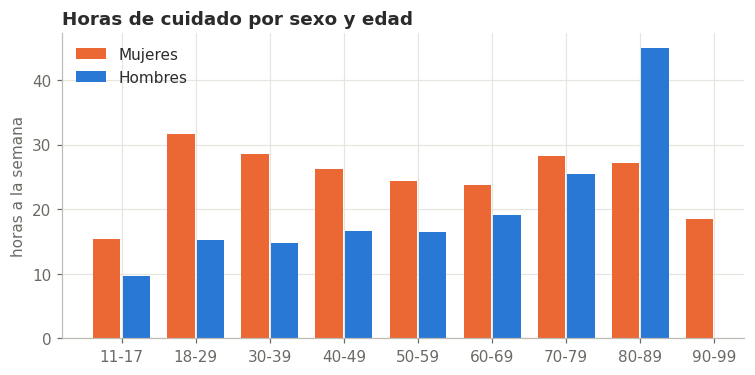

In [29]:
import numpy as np
fig, ax = plt.subplots(figsize=(8, 4.6))
a2 = alc.sort_values('total')
b = ax.barh(a2.alcaldia, a2.total, color=AZUL, height=.65)
etiquetas(ax, b, a2.pct_cdmx.values, horizontal=True, fmt='{:.1f}%', dx=a2.total.max() * .01, size=8)
ax.set_xlabel('personas que necesitan ayuda para bañarse, vestirse o comer'); ax.grid(axis='y', visible=False)
ax.set_title('Dependencia severa por alcaldía (etiqueta: % de la CDMX)')
nota(fig, 'Conteo, no tasa: refleja también el tamaño de la población de cada alcaldía.'); plt.show()

cc = c.reset_index(); x = np.arange(len(cc)); w = .4
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (s, colr) in enumerate([('Mujeres', NARANJA), ('Hombres', AZUL)]):
    b = ax.bar(x + (i - .5) * w, cc[s], w * .92, color=colr, label=s)
ax.set_xticks(x, cc.Edad); ax.set_ylabel('horas a la semana'); ax.legend(); ax.set_title('Horas de cuidado por sexo y edad')
plt.show()

<a id="s09"></a>

---

*Sección 09 · antes `09_coneval_pobreza_grupos_municipal.ipynb`*

# 09 — CONEVAL: pobreza por grupos poblacionales a escala municipal (CDMX, las 9 poblaciones)

## Ficha de fuente

| Campo | Valor |
|---|---|
| Fuente | CONEVAL, *Pobreza por grupos poblacionales a escala municipal 2010, 2015 y 2020* |
| Archivo | `Analysis/datos/CONEVAL_pobreza_grupos_poblacionales_municipal_2010_2015_2020.xlsx` (Anexo estadístico oficial) |
| URL de origen | https://www.coneval.org.mx/Medicion/Paginas/Pobreza_grupos_poblacionales_municipal_2010_2020.aspx |
| Fecha de descarga / consulta | 2026-09-24 |
| Unidad de observación | Municipio (para CDMX: alcaldía) × año × grupo poblacional |
| Grano | **Corte puntual**, no serie continua: 2010, 2015 y 2020 únicamente (periodicidad municipal de CONEVAL es de 5 años, no anual) |
| Clave | `Clave entidad` + `Clave municipio` (CDMX = entidad `09`, alcaldías `09002`–`09017`) |
| Factor de expansión | No aplica — son estimaciones agregadas ya publicadas por CONEVAL, no microdatos |
| Independencia de las observaciones | Cada fila es un municipio; los grupos poblacionales (hojas del archivo) **no son mutuamente excluyentes entre sí** — una misma persona puede contarse en varias hojas a la vez (p. ej. una mujer de 70 años cuenta en "mujeres" y en "adultmay") |
| Grupos disponibles (hojas) | `mujeres`, `hombres`, `nna` (0-17), `jovenes` (18-29), `adultos` (30-64), `adultmay` (65+), `pobindigena`, `rural`, `urbano` |

## Historial de esta versión

**2026-09-24, primera versión:** procesó solo la hoja `adultmay` (65+), por ser la población objetivo del proyecto (personas mayores con dependencia y discapacidad).

**2026-09-24, esta versión:** a petición explícita de Omar («no importa, incluye todo, aún no hay que delimitar mientras tengamos toda la data y hallazgos»), se amplía a las 9 poblaciones del archivo. **Esto no cambia la población objetivo del proyecto** (sigue siendo personas mayores y con discapacidad, según el objetivo candidato del 20 de septiembre): las 8 poblaciones adicionales se procesan como inventario disponible, no como una redefinición del alcance.

## Qué mide y qué NO mide

Mide **pobreza multidimensional** (CONEVAL) de cada grupo poblacional, por alcaldía, en 2010/2015/2020. Es un indicador de **vulnerabilidad económica del grupo**, no un indicador de cuidado, y no se refiere solo a personas mayores: incluye niñez, juventud, población indígena, rural y urbana.

**No sustituye ni resuelve** la regla de compatibilidad oferta–necesidad definida en `Analysis/matrices/matriz_tipologia_oferta_necesidad.csv` (2026-09-20): esto no es oferta de cuidado ni necesidad de cuidado medida directamente, para ninguna de las 9 poblaciones. Es contexto que puede correlacionarse después con indicadores de oferta/necesidad de cuidado una vez que esos cumplan la regla — no se usa aquí para construir ningún indicador territorial de cuidado.

In [30]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("datos/CONEVAL_pobreza_grupos_poblacionales_municipal_2010_2015_2020.xlsx")
assert DATA_PATH.exists(), f"No se encontró el archivo en {DATA_PATH.resolve()}"

xls = pd.ExcelFile(DATA_PATH)
print("Hojas disponibles:", xls.sheet_names)
assert len(xls.sheet_names) == 9, "Se esperaban 9 hojas"


Hojas disponibles: ['mujeres', 'hombres', 'nna', 'jovenes', 'adultos', 'adultmay', 'pobindigena', 'rural', 'urbano']


## 1. Función de parseo, generalizada a cualquier hoja

El archivo tiene un formato de reporte (encabezados en varias filas, columnas repetidas por año e indicador), no un formato tabular limpio. Se verificó que las 9 hojas comparten exactamente la misma estructura de encabezado (fila 7 = nombre de indicador, fila 8 = subencabezado Porcentaje/Precisión por año, datos desde la fila 9, en numeración de 1). Se parsea una sola función para las 9, no 9 parseos distintos escritos a mano.

In [31]:
GRUPOS = {
    "mujeres": "Población por sexo: mujeres",
    "hombres": "Población por sexo: hombres",
    "nna": "Niñas, niños y adolescentes (0 a 17 años)",
    "jovenes": "Jóvenes (18 a 29 años)",
    "adultos": "Adultos (30 a 64 años)",
    "adultmay": "Adultos mayores (65 años o más)",
    "pobindigena": "Población indígena",
    "rural": "Población rural",
    "urbano": "Población urbana",
}

def parse_sheet(sheet_name):
    raw = pd.read_excel(DATA_PATH, sheet_name=sheet_name, header=None)
    header_row = raw.iloc[6]      # fila 7 (1-indexed): nombre de cada bloque de indicador
    data = raw.iloc[8:].reset_index(drop=True)  # datos desde la fila 9 (1-indexed)

    indicator_names = [str(header_row.iloc[b]).strip() for b in range(7, 55, 6)]
    assert len(indicator_names) == 8, f"{sheet_name}: se esperaban 8 indicadores, hay {len(indicator_names)}"

    records = []
    for _, row in data.iterrows():
        clave_ent = row[0]
        clave_mun = row[2]
        if pd.isna(clave_ent) or pd.isna(clave_mun):
            continue
        pob = {2010: row[4], 2015: row[5], 2020: row[6]}
        for bi, base in enumerate(range(7, 55, 6)):
            indicador = indicator_names[bi]
            for anio, off in zip([2010, 2015, 2020], [0, 2, 4]):
                records.append({
                    "grupo": sheet_name,
                    "clave_entidad": clave_ent,
                    "clave_municipio": clave_mun,
                    "municipio": row[3],
                    "poblacion_grupo": pob[anio],
                    "anio": anio,
                    "indicador": indicador,
                    "porcentaje": row[base + off],
                    "precision": row[base + off + 1],
                })
    return pd.DataFrame(records)

print("Función definida. Se prueba con adultmay para comparar contra la versión anterior del notebook.")
prueba = parse_sheet("adultmay")
print(f"Filas: {len(prueba):,}")


Función definida. Se prueba con adultmay para comparar contra la versión anterior del notebook.


Filas: 59,256


In [32]:
dfs = []
for hoja in xls.sheet_names:
    d = parse_sheet(hoja)
    dfs.append(d)
    print(f"{hoja:12s} -> {len(d):,} filas")

todo = pd.concat(dfs, ignore_index=True)
print(f"\nTotal filas (9 poblaciones, todos los municipios): {len(todo):,}")


mujeres      -> 59,256 filas


hombres      -> 59,256 filas


nna          -> 59,256 filas


jovenes      -> 59,256 filas


adultos      -> 59,256 filas


adultmay     -> 59,256 filas


pobindigena  -> 58,920 filas


rural        -> 58,704 filas


urbano       -> 40,056 filas



Total filas (9 poblaciones, todos los municipios): 513,216


## 2. Filtro a las 16 alcaldías de la Ciudad de México (entidad `09`)

Se verifica, para cada una de las 9 poblaciones, que aparecen las 16 alcaldías — no se asume que todas las hojas tienen la misma cobertura territorial.

In [33]:
cdmx = todo[todo["clave_entidad"] == "09"].copy()

cobertura = {}
for hoja in xls.sheet_names:
    n = cdmx[cdmx["grupo"] == hoja]["clave_municipio"].nunique()
    cobertura[hoja] = n
    marca = "16/16" if n == 16 else f"{n}/16 — cobertura parcial"
    print(f"{hoja:12s} -> {marca}")

incompletas = [h for h, n in cobertura.items() if n < 16]
print()
if incompletas:
    print(f"Poblaciones con cobertura incompleta en CDMX: {incompletas}")
    print("No se fuerza a 16: se investiga en la siguiente celda antes de decidir qué significa.")
else:
    print("Las 9 poblaciones tienen las 16 alcaldías.")


mujeres      -> 16/16
hombres      -> 16/16
nna          -> 16/16
jovenes      -> 16/16
adultos      -> 16/16
adultmay     -> 16/16
pobindigena  -> 16/16
rural        -> 7/16 — cobertura parcial
urbano       -> 16/16

Poblaciones con cobertura incompleta en CDMX: ['rural']
No se fuerza a 16: se investiga en la siguiente celda antes de decidir qué significa.


### Por qué `rural` (y posiblemente otras) no cubre las 16 alcaldías

No se asume la razón — se verifica. La hipótesis más probable es que CONEVAL no reporta la hoja `rural` para alcaldías sin población rural (o sin muestra suficiente para estimarla), y que ese vacío no está codificado como "0 %" sino como fila ausente. Eso es exactamente la distinción que el proyecto exige no perderse: cero no es lo mismo que dato ausente.

In [34]:
alcaldias_16 = sorted(cdmx[cdmx.grupo == "adultmay"]["municipio"].unique())
for hoja in incompletas:
    presentes = set(cdmx[cdmx.grupo == hoja]["municipio"].unique())
    faltantes = sorted(set(alcaldias_16) - presentes)
    print(f"{hoja}: faltan {len(faltantes)} de 16 -> {faltantes}")


rural: faltan 9 de 16 -> ['Azcapotzalco', 'Benito Juárez', 'Coyoacán', 'Cuauhtémoc', 'Gustavo A. Madero', 'Iztacalco', 'Iztapalapa', 'Miguel Hidalgo', 'Venustiano Carranza']


## 3. Validación cruzada contra el dashboard *Observatorio de Cuidados* (INMUJERES)

Se repite la validación de la versión anterior (grupo `adultmay`, Azcapotzalco, 2020) para confirmar que la generalización del parseo no rompió nada.

In [35]:
chk = cdmx[
    (cdmx["grupo"] == "adultmay")
    & (cdmx["municipio"] == "Azcapotzalco")
    & (cdmx["anio"] == 2020)
    & (cdmx["indicador"] == "Población en situación de pobreza")
].iloc[0]

pob_65mas = chk["poblacion_grupo"]
pct = chk["porcentaje"]
personas_estimadas = pob_65mas * pct / 100

diff_pct = abs(pct - 16.3)
diff_personas = abs(personas_estimadas - 8881)
print(f"Azcapotzalco, 65+, 2020: {pct:.3f}% ({personas_estimadas:,.0f} personas) vs. dashboard OCU 16.3% (8,881)")
print(f"Diferencia: {diff_pct:.3f} pp / {diff_personas:.1f} personas")
assert diff_pct < 0.05 and diff_personas < 5, "No reproduce el dashboard — revisar antes de citar"
print("OK: la generalización reproduce el mismo resultado que la versión anterior del notebook.")


Azcapotzalco, 65+, 2020: 16.318% (8,881 personas) vs. dashboard OCU 16.3% (8,881)
Diferencia: 0.018 pp / 0.2 personas
OK: la generalización reproduce el mismo resultado que la versión anterior del notebook.


## 4. Tabla principal ampliada: % en situación de pobreza por alcaldía y población, 2020

Formato ancho: una fila por alcaldía, una columna por población, usando siempre el indicador más confiable del archivo ("Población en situación de pobreza", ver auditoría en la sección 5).

In [36]:
principal = cdmx[
    (cdmx["anio"] == 2020) & (cdmx["indicador"] == "Población en situación de pobreza")
][["municipio", "grupo", "porcentaje", "precision"]]

tabla_ancha = principal.pivot(index="municipio", columns="grupo", values="porcentaje")
orden_grupos = ["nna", "jovenes", "adultos", "adultmay", "mujeres", "hombres", "pobindigena", "rural", "urbano"]
tabla_ancha = tabla_ancha[orden_grupos].sort_values("adultmay", ascending=False)
tabla_ancha.round(1)


grupo,nna,jovenes,adultos,adultmay,mujeres,hombres,pobindigena,rural,urbano
municipio,,,,,,,,,
Milpa Alta,64.399736,53.621373,49.97474,45.783604,55.851541,53.462694,63.153168,52.84773,55.053036
Xochimilco,59.611967,51.652781,43.337038,32.937283,47.580063,48.851093,64.60286,56.774279,47.809698
Tláhuac,52.363167,42.939172,37.83734,32.869811,42.302385,42.524518,59.013872,40.841798,42.4371
Iztapalapa,54.076244,46.769102,39.877649,30.739191,43.904487,43.868754,57.93124,NaN,43.887307
La Magdalena Contreras,53.079847,46.893323,38.345256,30.370741,41.95009,43.105762,58.151218,68.448845,42.284236
Álvaro Obregón,48.893756,40.830595,33.61834,27.348429,37.468856,37.932333,59.141292,48.903599,37.689165
Tlalpan,52.16636,42.465142,34.902351,25.244566,39.315293,40.109348,56.90628,58.900002,39.413298
Gustavo A. Madero,43.871534,37.127536,30.628039,23.140982,33.130475,34.473541,58.067892,NaN,33.775466
Cuajimalpa de Morelos,43.110548,35.886303,28.387859,19.694138,31.572795,33.485487,58.76064,54.965801,31.987622


In [37]:
tabla_larga = principal.rename(columns={
    "porcentaje": "pct_pobreza_2020", "precision": "precision_pct_pobreza_2020"
}).merge(
    cdmx[(cdmx["anio"] == 2020) & (cdmx["indicador"] == "Población en situación de pobreza")][
        ["municipio", "grupo", "clave_municipio", "poblacion_grupo"]
    ],
    on=["municipio", "grupo"],
).sort_values(["grupo", "pct_pobreza_2020"], ascending=[True, False])[
    ["grupo", "clave_municipio", "municipio", "poblacion_grupo", "pct_pobreza_2020", "precision_pct_pobreza_2020"]
].reset_index(drop=True)

print(f"Filas: {len(tabla_larga)} (9 poblaciones x 16 alcaldías)")
tabla_larga.head(10)


Filas: 135 (9 poblaciones x 16 alcaldías)


,grupo,clave_municipio,municipio,poblacion_grupo,pct_pobreza_2020,precision_pct_pobreza_2020
0,adultmay,09009,Milpa Alta,11062,45.783604,✔
1,adultmay,09013,Xochimilco,40165,32.937283,✔
2,adultmay,09011,Tláhuac,28749,32.869811,✔
3,adultmay,09007,Iztapalapa,178837,30.739191,✔
4,adultmay,09008,La Magdalena Contreras,27751,30.370741,✔
5,adultmay,09010,Álvaro Obregón,87576,27.348429,✔
6,adultmay,09012,Tlalpan,70776,25.244566,✔
7,adultmay,09005,Gustavo A. Madero,151056,23.140982,✔
8,adultmay,09004,Cuajimalpa de Morelos,21798,19.694138,✔
9,adultmay,09017,Venustiano Carranza,50845,19.33893,✔


## 4b. Comparación entre poblaciones — un patrón que se repite en las 16 alcaldías

Nivel de evidencia: **confirmado**, con la salvedad de precisión declarada por población (sección 5).

In [38]:
tabla_ancha_num = tabla_ancha.apply(pd.to_numeric, errors="coerce")

print("Promedio simple de la CDMX (16 alcaldías, sin ponderar por población) por grupo, 2020:")
print(tabla_ancha_num.mean().round(1).sort_values())


Promedio simple de la CDMX (16 alcaldías, sin ponderar por población) por grupo, 2020:
grupo
adultmay       22.9
adultos        29.1
mujeres        32.7
urbano         32.7
hombres        32.9
jovenes        35.3
nna            43.0
pobindigena    54.2
rural          54.5
dtype: float64


In [39]:
razon_nna_adultmay = (tabla_ancha_num["nna"] / tabla_ancha_num["adultmay"]).round(2).sort_values(ascending=False)
print("Razón pobreza nna / pobreza adultmay, por alcaldía (2020):")
print(razon_nna_adultmay)
print()
print(f"La razón es mayor a 1 en las {int((razon_nna_adultmay > 1).sum())} de 16 alcaldías: la pobreza en niñez y adolescencia")
print("es mayor que en adultos mayores en TODAS las alcaldías de la ciudad, no solo en promedio.")


Razón pobreza nna / pobreza adultmay, por alcaldía (2020):
municipio
Cuauhtémoc                2.62
Benito Juárez             2.41
Coyoacán                  2.35
Miguel Hidalgo            2.23
Cuajimalpa de Morelos     2.19
Venustiano Carranza       2.14
Tlalpan                   2.07
Azcapotzalco              2.06
Gustavo A. Madero         1.90
Iztacalco                 1.87
Xochimilco                1.81
Álvaro Obregón            1.79
Iztapalapa                1.76
La Magdalena Contreras    1.75
Tláhuac                   1.59
Milpa Alta                1.41
dtype: float64

La razón es mayor a 1 en las 16 de 16 alcaldías: la pobreza en niñez y adolescencia
es mayor que en adultos mayores en TODAS las alcaldías de la ciudad, no solo en promedio.


La pobreza baja de forma monótona con la edad en las 16 alcaldías: niñez y adolescencia (43.0 % en promedio) > juventud (35.3 %) > adultos (29.1 %) > adultos mayores (22.9 %). La razón entre niñez y adultos mayores va de 1.4 a 1 (Milpa Alta) a 2.6 a 1 (Cuauhtémoc). Es un patrón conocido en México y coherente con el efecto de las pensiones no contributivas para personas mayores, no un hallazgo nuevo del equipo — se reporta aquí porque es información que ya estaba en el archivo y que el proyecto no había mirado.

**Qué NO dice esto.** No dice que el cuidado de la niñez sea más urgente que el de las personas mayores: mide pobreza económica, no necesidad de cuidado. La niñez, además, quedó fuera del nicho elegido por el proyecto desde la sección de selección de nicho (política pública ya la cubre con centros de cuidado infantil). Este patrón es contexto, no un argumento para cambiar el nicho.

Las poblaciones con mayor pobreza declarada son `pobindigena` (54.2 % en promedio) y `rural` (54.5 %, pero solo en las 7 alcaldías donde el archivo reporta esta hoja) — y son, a la vez, las que peor precisión estadística tienen (sección 5): la cifra más alta del archivo es también la menos confiable.

## 5. Auditoría de precisión estadística — las 9 poblaciones

Antes de citar cualquier celda que no sea el indicador principal, hay que saber cuál falla. Se audita cada población por separado: la confiabilidad no es la misma para niñez que para personas mayores.

In [40]:
banderas = cdmx[cdmx["anio"].isin([2010, 2015, 2020])].copy()
banderas["bandera"] = banderas["precision"].fillna("✔")

resumen = (
    banderas.groupby(["grupo", "indicador"])["bandera"]
    .value_counts()
    .unstack(fill_value=0)
)
for col in ["✔", "⚠", "❌"]:
    if col not in resumen.columns:
        resumen[col] = 0
resumen["total_celdas"] = resumen[["✔", "⚠", "❌"]].sum(axis=1)
resumen["pct_no_confiable"] = ((resumen["⚠"] + resumen["❌"]) / resumen["total_celdas"] * 100).round(1)
resumen = resumen[["✔", "⚠", "❌", "total_celdas", "pct_no_confiable"]]

print("Indicador principal ('Población en situación de pobreza'), por población, % de celdas no confiables:")
print(resumen.xs("Población en situación de pobreza", level="indicador")[["pct_no_confiable"]].sort_values("pct_no_confiable"))


Indicador principal ('Población en situación de pobreza'), por población, % de celdas no confiables:
bandera      pct_no_confiable
grupo                        
adultos                   4.2
mujeres                   4.2
nna                       4.2
urbano                    4.2
hombres                   6.2
jovenes                   8.3
adultmay                 12.5
pobindigena              37.5
rural                    52.4


In [41]:
celdas_problema = banderas[banderas["bandera"].isin(["⚠", "❌"])][
    ["grupo", "municipio", "indicador", "anio", "bandera", "porcentaje"]
].sort_values(["grupo", "indicador", "municipio", "anio"]).reset_index(drop=True)

n_total_posibles = sum(cobertura.values()) * 8 * 3  # celdas realmente existentes en el archivo, no 16 por población
print(f"Celdas con precisión reducida o sin dato: {len(celdas_problema)} de {n_total_posibles} posibles")
print(f"(suma real de alcaldías presentes por población x 8 indicadores x 3 años; no se asume 16 en poblaciones con cobertura parcial)")
print(f"Porcentaje: {100*len(celdas_problema)/n_total_posibles:.1f}%")


Celdas con precisión reducida o sin dato: 893 de 3240 posibles
(suma real de alcaldías presentes por población x 8 indicadores x 3 años; no se asume 16 en poblaciones con cobertura parcial)
Porcentaje: 27.6%


## 6. Guardar resultados

Tres archivos:
1. `09_pobreza_alcaldia_cdmx_todos_grupos.csv` — formato largo, las 9 poblaciones, indicador principal, 2020.
2. `09_pobreza_65mas_alcaldia_cdmx.csv` — **sin cambios respecto a la versión anterior** (se conserva por compatibilidad con el Documento Integrado v0.3, que ya la cita).
3. `09_auditoria_precision_cdmx_todos_grupos.csv` — todas las celdas con precisión reducida o suprimida, las 9 poblaciones, los 8 indicadores, los 3 años.

In [42]:
out_dir = Path("resultados")
out_dir.mkdir(exist_ok=True)

tabla_larga.to_csv(out_dir / "09_pobreza_alcaldia_cdmx_todos_grupos.csv", index=False, encoding="utf-8-sig")
celdas_problema.to_csv(out_dir / "09_auditoria_precision_cdmx_todos_grupos.csv", index=False, encoding="utf-8-sig")

# 09_pobreza_65mas_alcaldia_cdmx.csv se conserva sin cambios (misma lógica, mismo resultado, verificado en la sección 3)
tabla_65 = tabla_larga[tabla_larga.grupo == "adultmay"][
    ["clave_municipio", "municipio", "poblacion_grupo", "pct_pobreza_2020", "precision_pct_pobreza_2020"]
].rename(columns={"poblacion_grupo": "poblacion_65mas"}).reset_index(drop=True)
tabla_65.to_csv(out_dir / "09_pobreza_65mas_alcaldia_cdmx.csv", index=False, encoding="utf-8-sig")

print("Guardado:")
print(" -", out_dir / "09_pobreza_alcaldia_cdmx_todos_grupos.csv", f"({len(tabla_larga)} filas)")
print(" -", out_dir / "09_auditoria_precision_cdmx_todos_grupos.csv", f"({len(celdas_problema)} filas)")
print(" -", out_dir / "09_pobreza_65mas_alcaldia_cdmx.csv", f"({len(tabla_65)} filas, sin cambios)")


Guardado:
 - resultados/09_pobreza_alcaldia_cdmx_todos_grupos.csv (135 filas)
 - resultados/09_auditoria_precision_cdmx_todos_grupos.csv (893 filas)
 - resultados/09_pobreza_65mas_alcaldia_cdmx.csv (16 filas, sin cambios)


## 7. Qué cambia frente a la versión anterior de este notebook, y qué no

- **No cambia** la tabla ni el archivo `09_pobreza_65mas_alcaldia_cdmx.csv` que ya usa el Documento Integrado v0.3: se verificó en la sección 3 que la generalización del parseo reproduce el mismo resultado.
- **Se agrega** el inventario completo de las 9 poblaciones. Esto es información disponible, no una redefinición de la población objetivo del proyecto, que sigue siendo personas mayores con dependencia y personas con discapacidad (objetivo candidato del 20 de septiembre de 2026).
- Las 8 poblaciones adicionales (niñez, juventud, adultos, mujeres, hombres, indígena, rural, urbana) permiten comparar el nivel de pobreza del grupo 65+ contra otros grupos, pero **no convierten a ninguno de ellos en población de este proyecto** sin que el equipo lo decida explícitamente.

## 8. Límites — no dar por resuelto lo que no se resolvió

1. **No es serie continua.** 2010, 2015, 2020 son tres cortes puntuales (periodicidad municipal de CONEVAL = 5 años).
2. **No es indicador de cuidado, para ninguna de las 9 poblaciones.** Es pobreza del grupo, no necesidad de cuidado ni oferta de cuidado. No se usa para construir ningún indicador territorial de cuidado sin pasar antes por la regla de compatibilidad de `matriz_tipologia_oferta_necesidad.csv`.
3. **Las carencias específicas (vivienda sobre todo) siguen sin ser confiables por alcaldía**, y esto varía por población — ver la tabla de la sección 5. Solo el indicador principal ("Población en situación de pobreza") se recomienda citar sin advertencia adicional, y solo para 2020.
4. **Los grupos no son mutuamente excluyentes.** Una misma persona puede contarse en varias hojas (por ejemplo, "mujeres" y "adultmay"). No se pueden sumar poblaciones de distintas hojas para obtener un total.
5. **No se ha hecho ningún cruce con oferta o necesidad de cuidado**, para ninguna población. Queda como contexto disponible.
6. **Ampliar la cobertura poblacional no es delimitar el proyecto.** El equipo pidió explícitamente tener todo el inventario disponible; esto no reemplaza la decisión, pendiente, de a qué población se dirige el programa.

**Pendiente de doble revisión** (Daniel o Alondra Danae), igual que el resto de los notebooks del proyecto.

<a id="s13"></a>

---

*Sección 13 · antes `13_rezago_social_ageb_cdmx.ipynb`*

# 13 · Rezago social por AGEB urbana (CONEVAL 2020) y marginación municipal (CONAPO 2020) en la CDMX.

```text
Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Creado: 2026-10-06. Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/

Para qué existe
  Capa de CONTEXTO DE VULNERABILIDAD territorial para la pestaña Territorio del Observatorio.
  NO mide necesidad ni demanda de cuidado: el rezago social resume carencias de educación, salud
  (derechohabiencia) y vivienda. Usarlo como "demanda de cuidado" sería un error de concepto.

Qué representa una fila de la fuente
  grs_ageb_2020.csv: una AGEB urbana (Área Geoestadística Básica) del Censo 2020. Dato ya agregado,
  sin factor de expansión (censo). Clave: folio_ageb (13 caracteres: entidad 2 + municipio 3 +
  localidad 4 + AGEB 4). Las AGEB no son independientes (vecindad espacial).
  Indicadores i_* = porcentajes. i_sdsalud = % de la población sin derechohabiencia a servicios de salud
  (denominador: población total). grs = grado de rezago social (Muy bajo ... Muy alto).
  Las columnas fn_* son copias numéricas de las columnas originales (verificado: coinciden en todas las
  filas con dato; las claves con letra, p. ej. "003A", quedan vacías). No se usan.

Hallazgos de calidad que este script documenta (y por qué importan)
  - INEGI/CONEVAL suprimen los indicadores ("*") en AGEB con muy poca población, pero esas AGEB conservan
    un grado de rezago. En la CDMX, varias AGEB "Muy alto" tienen de 1 a 7 habitantes. Por eso los
    agregados de este script EXCLUYEN las AGEB con indicadores suprimidos y reportan cuántas son.
  - Cobertura: la suma de población de las AGEB urbanas se compara con la población total de la CDMX
    (Censo 2020: 9,209,944, mismo dato que resultados/05_tasas_y_anclajes.csv).

Salidas
  resultados/13_rezago_ageb_cdmx.csv          una fila por AGEB urbana de la CDMX (dato público agregado)
  resultados/13_rezago_por_alcaldia.csv       16 alcaldías: capas para el Observatorio + marginación CONAPO
  resultados/13_calidad_rezago.csv            chequeos de cobertura y supresión

Limitaciones (leer antes de citar)
  - Un solo corte (2020). No hay tendencia.
  - Agregar AGEB a alcaldía pondera por población; i_sdsalud usa población total como denominador, así
    que el promedio ponderado es exacto para la población cubierta por AGEB urbanas.
  - El grado de rezago es relativo al país: casi todas las AGEB de la CDMX quedan en Bajo o Muy bajo.
    Diferencias pequeñas entre alcaldías no son diferencias de necesidad de cuidado.
  - Falacia ecológica: que una AGEB tenga rezago medio no dice nada de un hogar concreto.
  - El índice de marginación municipal de CONAPO clasifica a las 16 alcaldías como "Muy bajo"; se
    reporta en la tabla, pero no se usa como capa porque no distingue entre alcaldías.
```

*Convertido de `13_rezago_social_ageb_cdmx.py` el 2026-10-07 sin cambiar el cálculo; se agregaron las gráficas al final.*

In [43]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from estilo_graficas import *
estilo()
%matplotlib inline

In [44]:
from pathlib import Path
import numpy as np, pandas as pd

OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
POB_CDMX_CENSO = 9209944
IND = ['i_analf', 'i_asistesc_6a14', 'i_asistesc_015a24', 'i_edbasinc', 'i_sdsalud', 'i_hacinamiento', 'i_noagua',
       'i_nosan', 'i_nodren', 'i_noelec', 'i_ptierra', 'i_nolav', 'i_noref', 'i_notelefono_fijo', 'i_nocelular',
       'i_nocomputadora', 'i_nointernet']
ORDEN = ['Muy bajo', 'Bajo', 'Medio', 'Alto', 'Muy alto']

a = pd.read_csv('datos/coneval_irs/grs_ageb_2020.csv.zip', dtype=str)
a = a[a.clave_entidad == '9'].copy()
for c in IND + ['poblacion', 'viviendas_habitadas']:
    a[c + '_supr'] = a[c].eq('*')
    a[c] = pd.to_numeric(a[c].where(~a[c].eq('*')), errors='coerce')
a['suprimida'] = a[[c + '_supr' for c in IND]].any(axis=1)
assert a.folio_ageb.str.len().eq(13).all() and not a.folio_ageb.duplicated().any(), 'Clave de AGEB inválida o repetida'
assert set(a.grs.unique()) <= set(ORDEN), a.grs.unique()
a['clave_alcaldia'] = a.clave_municipio.astype(int)

cols = ['folio_ageb', 'clave_alcaldia', 'municipio', 'localidad', 'clave_ageb', 'poblacion', 'viviendas_habitadas'] + IND + ['grs', 'suprimida']
a[cols].rename(columns={'municipio': 'alcaldia'}).to_csv(OUT / '13_rezago_ageb_cdmx.csv', index=False, encoding='utf-8-sig')

v = a[~a.suprimida]
MEDIO_MAS = ['Medio', 'Alto', 'Muy alto']


def wavg(g, col, w='poblacion'):
    m = g[col].notna() & g[w].notna()
    return float(np.average(g.loc[m, col], weights=g.loc[m, w]))


filas = []
for (cve, alc), g in v.groupby(['clave_alcaldia', 'municipio']):
    todas = a[a.clave_alcaldia == cve]
    pob = g.poblacion.sum()
    filas.append(dict(
        clave_alcaldia=cve, alcaldia=alc, n_ageb=len(todas), n_ageb_suprimidas=int(todas.suprimida.sum()),
        poblacion_ageb_validas=int(pob),
        pct_pob_rezago_medio_o_mas=round(100 * g.loc[g.grs.isin(MEDIO_MAS), 'poblacion'].sum() / pob, 2),
        pct_ageb_rezago_medio_o_mas=round(100 * g.grs.isin(MEDIO_MAS).mean(), 2),
        n_ageb_rezago_medio_o_mas=int(g.grs.isin(MEDIO_MAS).sum()),
        pct_sin_derechohabiencia=round(wavg(g, 'i_sdsalud'), 2),
        sdsalud_p10_ageb=round(g.i_sdsalud.quantile(.1), 1), sdsalud_p90_ageb=round(g.i_sdsalud.quantile(.9), 1),
        pct_edbasinc_aprox=round(wavg(g, 'i_edbasinc'), 2),
        pct_viv_hacinamiento=round(wavg(g, 'i_hacinamiento', 'viviendas_habitadas'), 2),
        **{f'n_ageb_{k.lower().replace(" ", "_")}': int((g.grs == k).sum()) for k in ORDEN}))
alc = pd.DataFrame(filas)

imm = pd.read_csv('datos/conapo_marginacion/imm_2020.csv')
imm = imm[imm.CVE_ENT == 9][['CVE_MUN', 'IM_2020', 'GM_2020', 'IMN_2020']].rename(
    columns={'CVE_MUN': 'clave_alcaldia', 'IM_2020': 'conapo_im_2020', 'GM_2020': 'conapo_gm_2020', 'IMN_2020': 'conapo_imn_2020'})
alc = alc.merge(imm, on='clave_alcaldia', how='left', validate='1:1')
assert len(alc) == 16 and alc.conapo_im_2020.notna().all(), 'Faltan alcaldías en el cruce con CONAPO'
alc.to_csv(OUT / '13_rezago_por_alcaldia.csv', index=False, encoding='utf-8-sig')

pob_ageb = a.poblacion.sum()
ent = pd.read_csv('datos/coneval_irs/irs_entidad_nacional_2020.csv')
ent_sdsalud = float(ent.loc[ent.clave_entidad == 9, 'i_sdsalud'].iloc[0])
cal = pd.DataFrame([
    dict(chequeo='AGEB urbanas en la CDMX', valor=len(a), nota='grs_ageb_2020.csv, clave_entidad = 9'),
    dict(chequeo='Población en AGEB urbanas', valor=int(pob_ageb), nota=f'{100 * pob_ageb / POB_CDMX_CENSO:.1f} % de la población total de la CDMX (Censo 2020)'),
    dict(chequeo='AGEB con indicadores suprimidos (*)', valor=int(a.suprimida.sum()),
         nota=f'población {int(a.loc[a.suprimida, "poblacion"].sum())}; se excluyen de los agregados'),
    dict(chequeo='AGEB "Alto" o "Muy alto" con indicadores suprimidos', valor=int((a.suprimida & a.grs.isin(['Alto', 'Muy alto'])).sum()),
         nota='grado asignado a AGEB casi vacías: no interpretarlas como focos de rezago'),
    dict(chequeo='AGEB "Muy alto" válidas (sin supresión)', valor=int((~a.suprimida & (a.grs == 'Muy alto')).sum()),
         nota=f'población {int(a.loc[~a.suprimida & (a.grs == "Muy alto"), "poblacion"].sum())}'),
    dict(chequeo='Población en AGEB válidas con rezago Medio o más', valor=int(v.loc[v.grs.isin(MEDIO_MAS), 'poblacion'].sum()),
         nota=f'{100 * v.loc[v.grs.isin(MEDIO_MAS), "poblacion"].sum() / v.poblacion.sum():.1f} % de la población en AGEB válidas'),
    dict(chequeo='% sin derechohabiencia, CDMX: promedio de AGEB válidas ponderado por población', valor=round(wavg(v, 'i_sdsalud'), 2),
         nota=f'control: CONEVAL IRS por entidad 2020 = {ent_sdsalud:.2f} % (irs_entidad_nacional_2020.csv)'),
    dict(chequeo='Alcaldías con marginación CONAPO distinta de "Muy bajo"', valor=int((alc.conapo_gm_2020 != 'Muy bajo').sum()),
         nota=f'IM_2020 va de {alc.conapo_im_2020.min():.1f} a {alc.conapo_im_2020.max():.1f}'),
])
cal.to_csv(OUT / '13_calidad_rezago.csv', index=False, encoding='utf-8-sig')
print(cal.to_string(index=False))
print(alc[['alcaldia', 'n_ageb', 'n_ageb_suprimidas', 'pct_pob_rezago_medio_o_mas', 'pct_sin_derechohabiencia',
           'sdsalud_p10_ageb', 'sdsalud_p90_ageb', 'conapo_gm_2020']].sort_values('pct_pob_rezago_medio_o_mas', ascending=False).to_string(index=False))

                                                                       chequeo      valor                                                                            nota
                                                       AGEB urbanas en la CDMX    2410.00                                            grs_ageb_2020.csv, clave_entidad = 9
                                                     Población en AGEB urbanas 9130248.00                            99.1 % de la población total de la CDMX (Censo 2020)
                                           AGEB con indicadores suprimidos (*)      10.00                                      población 58; se excluyen de los agregados
                           AGEB "Alto" o "Muy alto" con indicadores suprimidos       4.00       grado asignado a AGEB casi vacías: no interpretarlas como focos de rezago
                                       AGEB "Muy alto" válidas (sin supresión)       3.00                                                             

## Gráficas
Contexto de vulnerabilidad, **no necesidad de cuidado**. AGEB con datos suprimidos excluidas.

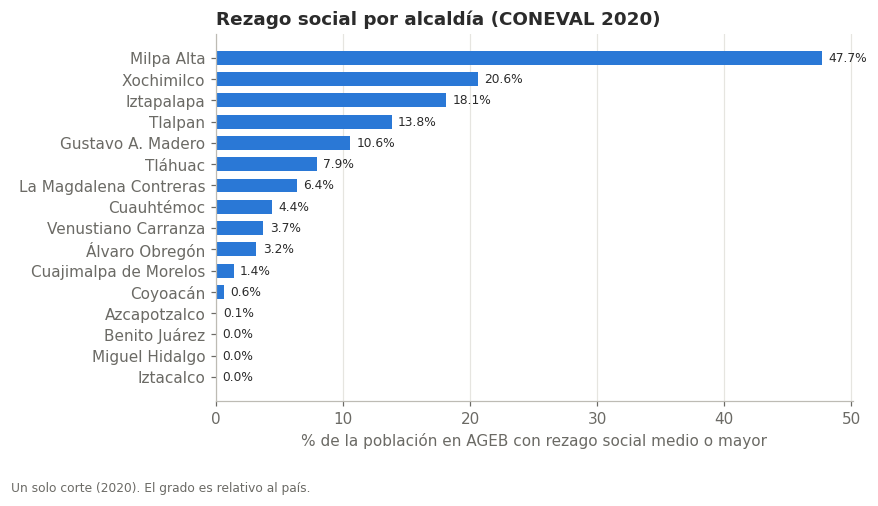

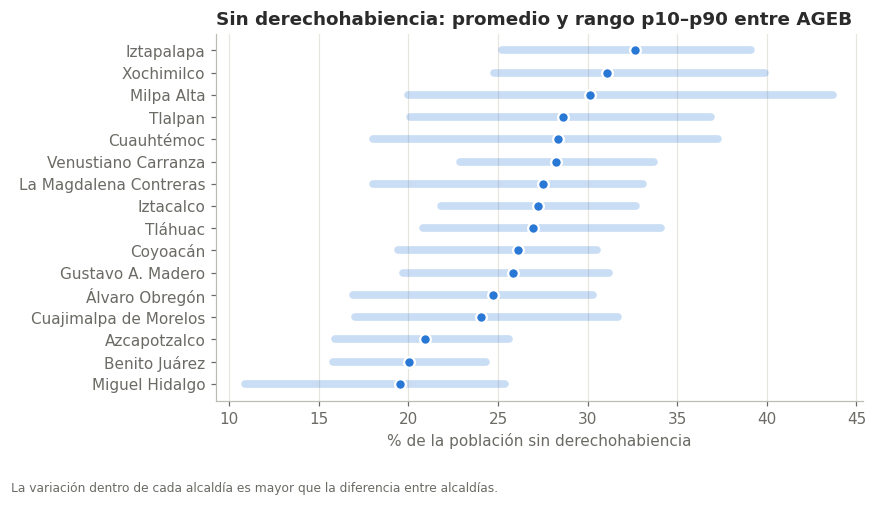

In [45]:
a2 = alc.sort_values('pct_pob_rezago_medio_o_mas')
fig, ax = plt.subplots(figsize=(8, 4.6))
b = ax.barh(a2.alcaldia, a2.pct_pob_rezago_medio_o_mas, color=AZUL, height=.65)
etiquetas(ax, b, a2.pct_pob_rezago_medio_o_mas.values, horizontal=True, fmt='{:.1f}%', dx=.5, size=8)
ax.set_xlabel('% de la población en AGEB con rezago social medio o mayor'); ax.grid(axis='y', visible=False)
ax.set_title('Rezago social por alcaldía (CONEVAL 2020)')
nota(fig, 'Un solo corte (2020). El grado es relativo al país.'); plt.show()

a3 = alc.sort_values('pct_sin_derechohabiencia').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 4.6))
for i, r in a3.iterrows():
    ax.plot([r.sdsalud_p10_ageb, r.sdsalud_p90_ageb], [i, i], color=AZUL, lw=5, alpha=.25, solid_capstyle='round')
    ax.plot(r.pct_sin_derechohabiencia, i, 'o', color=AZUL, ms=7, mec='white', mew=1.5)
ax.set_yticks(range(len(a3)), a3.alcaldia); ax.grid(axis='y', visible=False)
ax.set_xlabel('% de la población sin derechohabiencia'); ax.set_title('Sin derechohabiencia: promedio y rango p10–p90 entre AGEB')
nota(fig, 'La variación dentro de cada alcaldía es mayor que la diferencia entre alcaldías.'); plt.show()

<a id="s17"></a>

---

# 17 · Contexto estatal: personas de 60+ por entidad (ENIGH 2022, CONEVAL) y marginación (CONAPO 2020)

```text
Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Creado: 2026-10-08. Ejecutar desde la carpeta Analysis/

Para qué existe
  Dar a la pestaña «¿Dónde?» un marco nacional: dónde queda la CDMX frente a las otras 31 entidades en
  indicadores de la población de 60+ que condicionan la necesidad de cuidado (pobreza, seguridad social,
  salud, vivir sola). No mide necesidad de cuidado ni dependencia: ninguna de estas variables lo hace.

Qué representa una fila de la fuente
  pobreza22.csv (programa de cálculo del CONEVAL sobre la ENIGH 2022): una persona de un hogar.
  Clave: folioviv + foliohog + numren. factor = factor de expansión del hogar, aplicado a cada integrante.
  Diseño: estratos est_dis, UPM upm. Las personas de un mismo hogar/UPM no son independientes:
  por eso el error estándar se calcula por diseño (linealización de Taylor), no como muestreo aleatorio simple.
  La ENIGH 2022 es representativa por entidad federativa (no por alcaldía).
  ime_2020.csv (CONAPO): una entidad. Censo 2020, sin error muestral.

Qué permite afirmar
  - Nivel de cada indicador por entidad en 2022, con IC 90 %, y la posición de la CDMX.
Qué NO permite afirmar
  - Tendencias (un solo año en esta sección).
  - Nada por alcaldía ni por municipio.
  - Necesidad o demanda de cuidado: la carencia de seguridad social del CONEVAL cuenta como cubiertas a las
    personas de 65+ con pensión no contributiva, por eso sus niveles son bajos para ese grupo.
  - «Vive sola» = hogar unipersonal; no distingue si hay otros hogares en la misma vivienda ni si recibe ayuda.
```


In [ ]:
from pathlib import Path
import zipfile
import numpy as np, pandas as pd

OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
COLS = ['folioviv', 'foliohog', 'numren', 'est_dis', 'upm', 'factor', 'ent', 'edad', 'pobreza', 'pobreza_e', 'ic_segsoc', 'ic_asalud']
with zipfile.ZipFile('datos/enigh2022_coneval/pobreza22.csv.zip') as z:
    p = pd.read_csv(z.open('pobreza22.csv'), usecols=COLS, dtype={'folioviv': str, 'foliohog': str})
assert not p.duplicated(['folioviv', 'foliohog', 'numren']).any(), 'Persona repetida'
assert p.ent.between(1, 32).all() and p.ent.nunique() == 32

# Grano: una fila = una persona del hogar. factor = factor de expansión del hogar (aplica a cada integrante).
p['hog'] = p.folioviv + '-' + p.foliohog
p['tam'] = p.groupby('hog').numren.transform('size')
p['uno'] = 1
p['m60'] = (p.edad >= 60).astype(int)
p['sola60'] = ((p.edad >= 60) & (p.tam == 1)).astype(int)            # hogar unipersonal de 60+
for c in ['pobreza', 'ic_segsoc', 'ic_asalud']:
    p[c + '_60'] = np.where(p.edad >= 60, p[c], 0.0)
p.loc[p.pobreza.isna(), 'pobreza_60'] = np.nan                        # 14 personas sin clasificación de pobreza
h = (p.groupby('hog').agg(est_dis=('est_dis', 'first'), upm=('upm', 'first'), factor=('factor', 'first'),
                          ent=('ent', 'first'), con60=('m60', 'max')).reset_index())
h['uno'] = 1


def razon(d, y, x):
    """Razón Σw·y / Σw·x con error estándar por linealización de Taylor (UPM con reemplazo dentro de cada estrato)."""
    d = d[d[y].notna() & d[x].notna()]
    w = d.factor; X = (w * d[x]).sum(); R = (w * d[y]).sum() / X
    z = w * (d[y] - R * d[x]) / X
    t = pd.DataFrame({'h': d.est_dis, 'u': d.upm, 'z': z}).groupby(['h', 'u']).z.sum().reset_index()
    g = t.groupby('h').z; nh = g.transform('size')
    v = (nh / (nh - 1) * (t.z - g.transform('mean')) ** 2)[nh > 1].sum()
    return R * 100, np.sqrt(v) * 100, int(d[x].gt(0).sum())


IND = [  # clave, base, numerador, denominador, universo, definición
    ('pct_pob60', 'p', 'm60', 'uno', 'personas', 'Personas de 60 años y más, % de la población'),
    ('hog60', 'h', 'con60', 'uno', 'hogares', 'Hogares con al menos una persona de 60 y más'),
    ('pobreza60', 'p', 'pobreza_60', 'm60', 'personas de 60+', 'Personas de 60+ en situación de pobreza (CONEVAL)'),
    ('segsoc60', 'p', 'ic_segsoc_60', 'm60', 'personas de 60+', 'Personas de 60+ con carencia por acceso a la seguridad social'),
    ('salud60', 'p', 'ic_asalud_60', 'm60', 'personas de 60+', 'Personas de 60+ con carencia por acceso a los servicios de salud'),
    ('sola60', 'p', 'sola60', 'm60', 'personas de 60+', 'Personas de 60+ que viven solas (hogar unipersonal)'),
]
filas = []
for e in [0] + sorted(p.ent.unique()):
    bases = {'p': p if e == 0 else p[p.ent == e], 'h': h if e == 0 else h[h.ent == e]}
    for k, b, y, x, u, dfn in IND:
        r, se, n = razon(bases[b], y, x)
        cv = se / r * 100
        filas.append(dict(clave_entidad=int(e), indicador=k, definicion=dfn, pct=round(r, 2), ee=round(se, 3),
                          cv=round(cv, 2), li90=round(r - 1.645 * se, 2), ls90=round(r + 1.645 * se, 2), n_muestra=n,
                          universo=u, precision='alta' if cv <= 15 else 'moderada' if cv <= 30 else 'baja'))
est = pd.DataFrame(filas)

nom = pd.read_csv('datos/coneval_irs/irs_entidad_nacional_2020.csv')[['clave_entidad', 'entidad_federativa']]
est = est.merge(nom, on='clave_entidad', how='left')
assert est.entidad_federativa.notna().all()
est.to_csv(OUT / '17_enigh_60mas_por_entidad.csv', index=False, encoding='utf-8-sig')

# Validación contra cifras publicadas por CONEVAL (comunicado 07/2023, medición 2022): pobreza 36.3 %, extrema 7.1 %.
wv = p.factor
val = pd.DataFrame([
    dict(chequeo='Pobreza nacional 2022 (toda la población)', calculado=round((wv * p.pobreza).sum() / wv[p.pobreza.notna()].sum() * 100, 1), publicado=36.3,
         fuente='CONEVAL, Comunicado 07, 10/08/2023 (consultado 08/10/2026)'),
    dict(chequeo='Pobreza extrema nacional 2022', calculado=round((wv * p.pobreza_e).sum() / wv[p.pobreza_e.notna()].sum() * 100, 1), publicado=7.1,
         fuente='CONEVAL, Comunicado 07, 10/08/2023 (consultado 08/10/2026)'),
])
val['coincide'] = (val.calculado - val.publicado).abs() < 0.05
val.to_csv(OUT / '17_validacion_enigh.csv', index=False, encoding='utf-8-sig')
assert val.coincide.all(), val

# Marginación estatal (CONAPO 2020): censo, sin error muestral. Contexto, no necesidad de cuidado.
im = pd.read_csv('datos/conapo_marginacion/ime_2020.csv')[['CVE_ENT', 'NOM_ENT', 'POB_TOT', 'IM_2020', 'GM_2020', 'IMN_2020']]
assert len(im) == 32
# Ojo con el sentido: en la metodología 2020 de CONAPO un IM_2020 MÁS BAJO significa MÁS marginación
# (Guerrero, 10.99, es la entidad más marginada; Nuevo León, 23.44, la menos). Verificado con GM_2020.
im['lugar_nacional'] = im.IM_2020.rank(ascending=True, method='min').astype(int)   # 1 = más marginada
assert im.loc[im.lugar_nacional == 1, 'GM_2020'].eq('Muy alto').all()
im.rename(columns={'CVE_ENT': 'clave_entidad'}).to_csv(OUT / '17_marginacion_entidad_conapo_2020.csv', index=False, encoding='utf-8-sig')

display(val)
display(est[est.clave_entidad.isin([0, 9])].pivot(index='indicador', columns='entidad_federativa', values='pct'))
print('CV máximo por indicador:'); display(est.groupby('indicador').cv.max())
